# 03 · Phân tích khám phá dữ liệu (T08)
Mỗi hình lưu vào `images/eda_*.png` và được dùng trong Phần 3 báo cáo.

In [1]:
import sys, json, pandas as pd
sys.path.insert(0, 'src')
pd.set_option('display.max_colwidth', 80)
from IPython.display import Image, display

In [2]:
from kimochi import eda
st = eda.run_all()

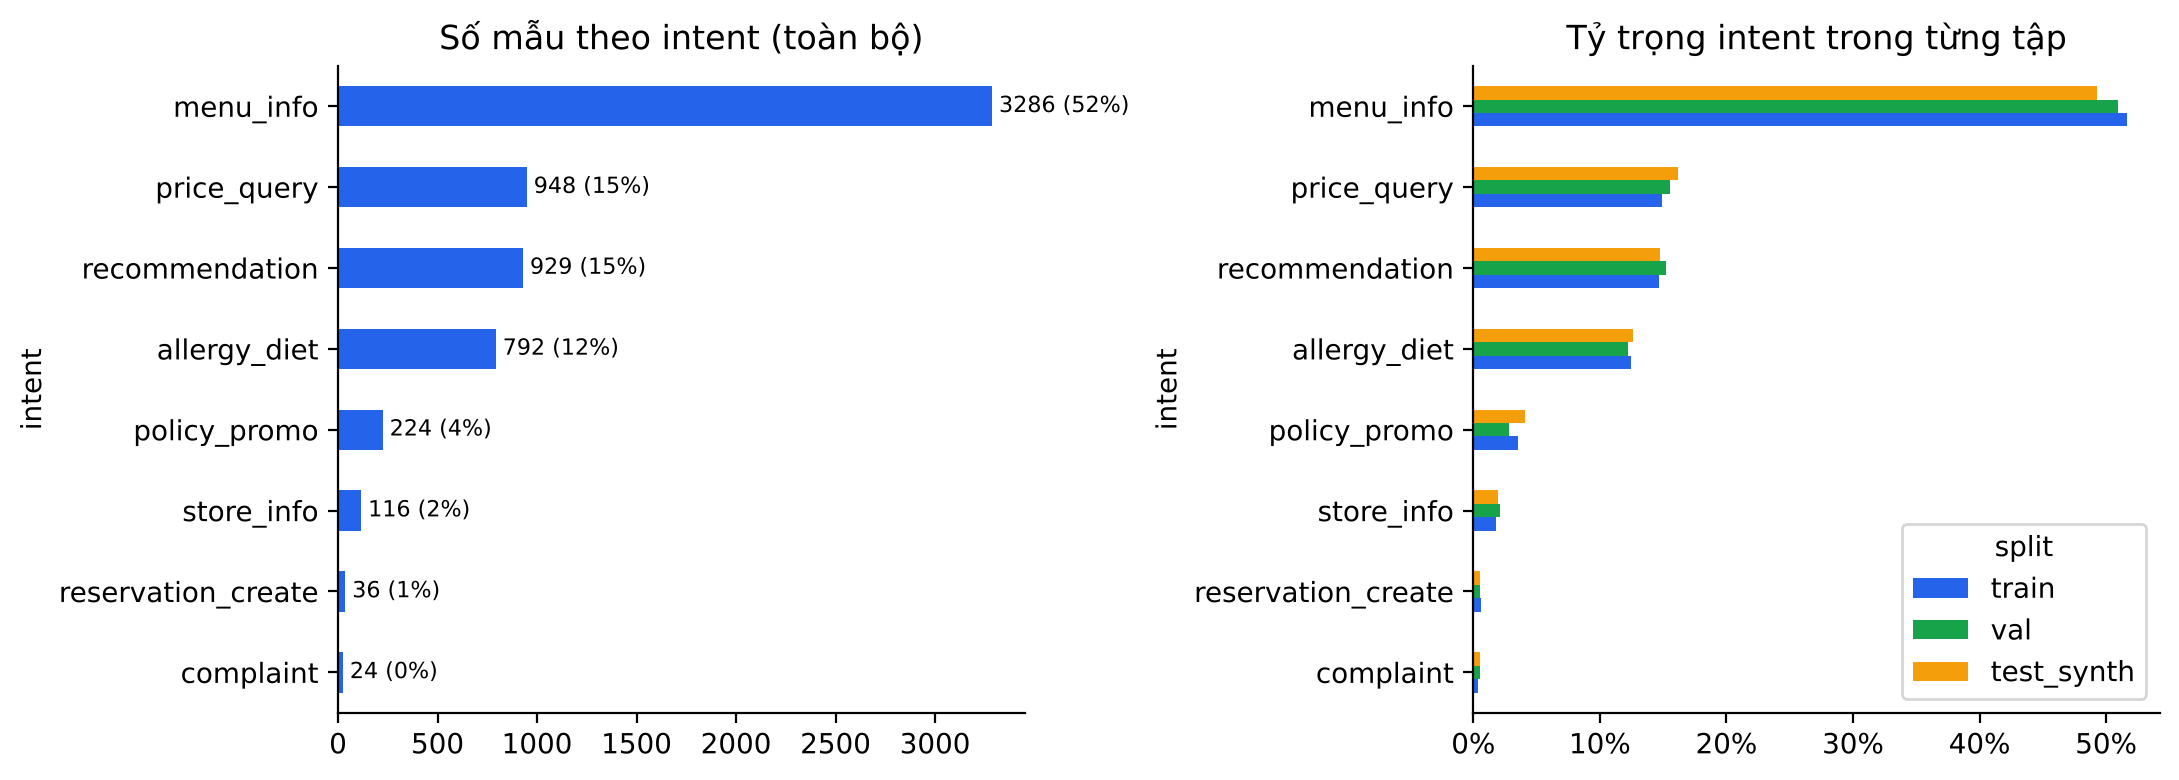

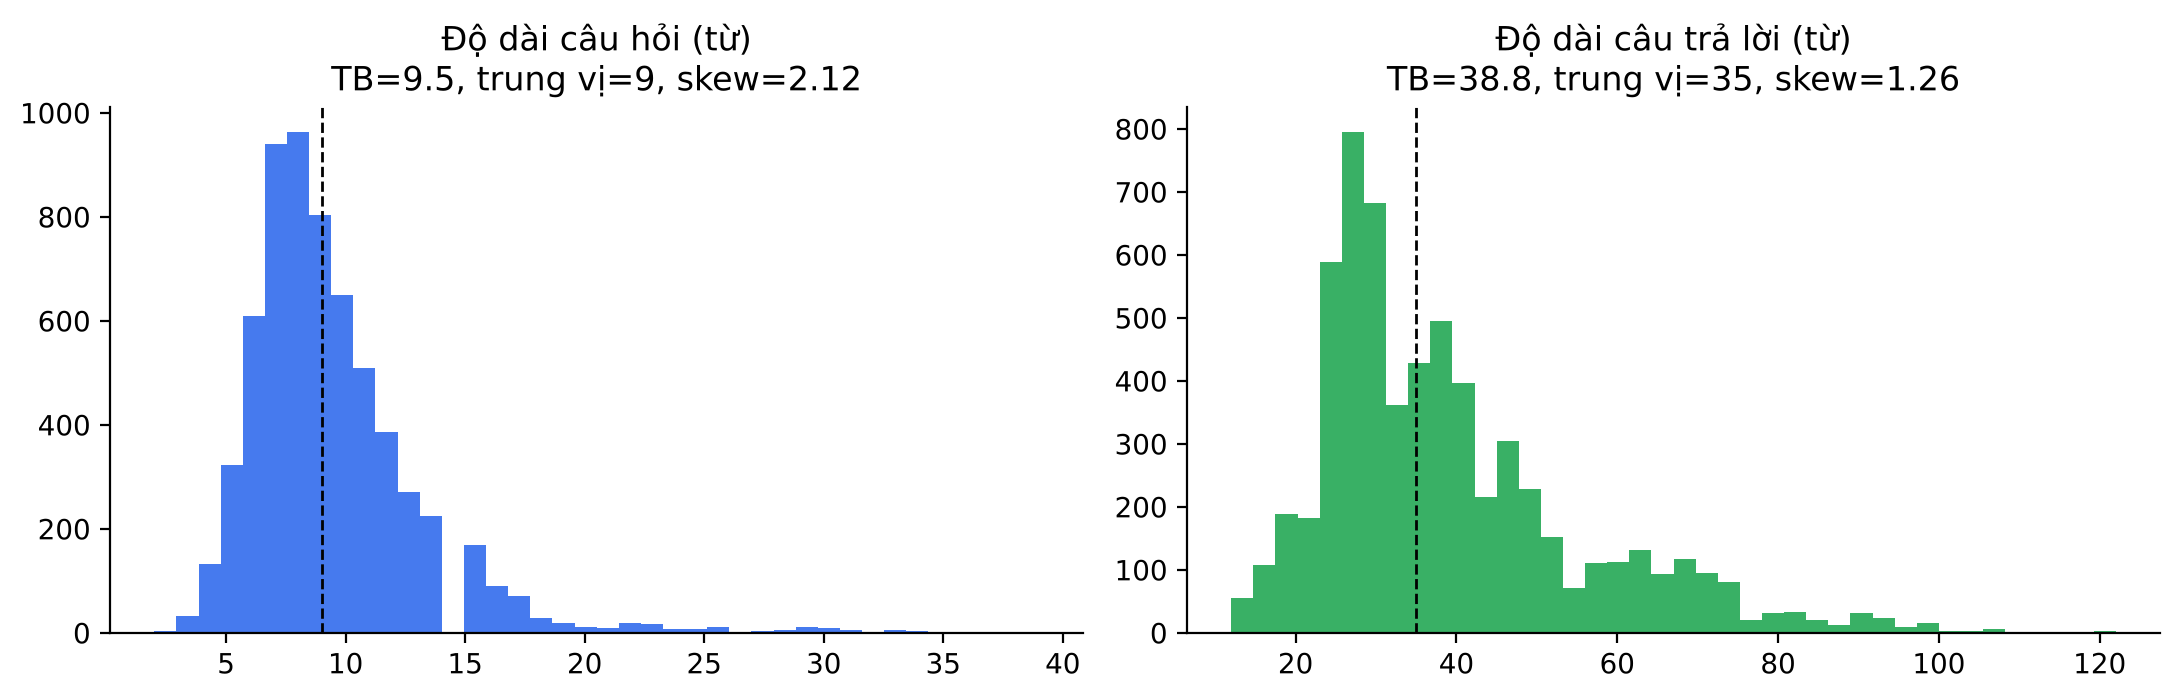

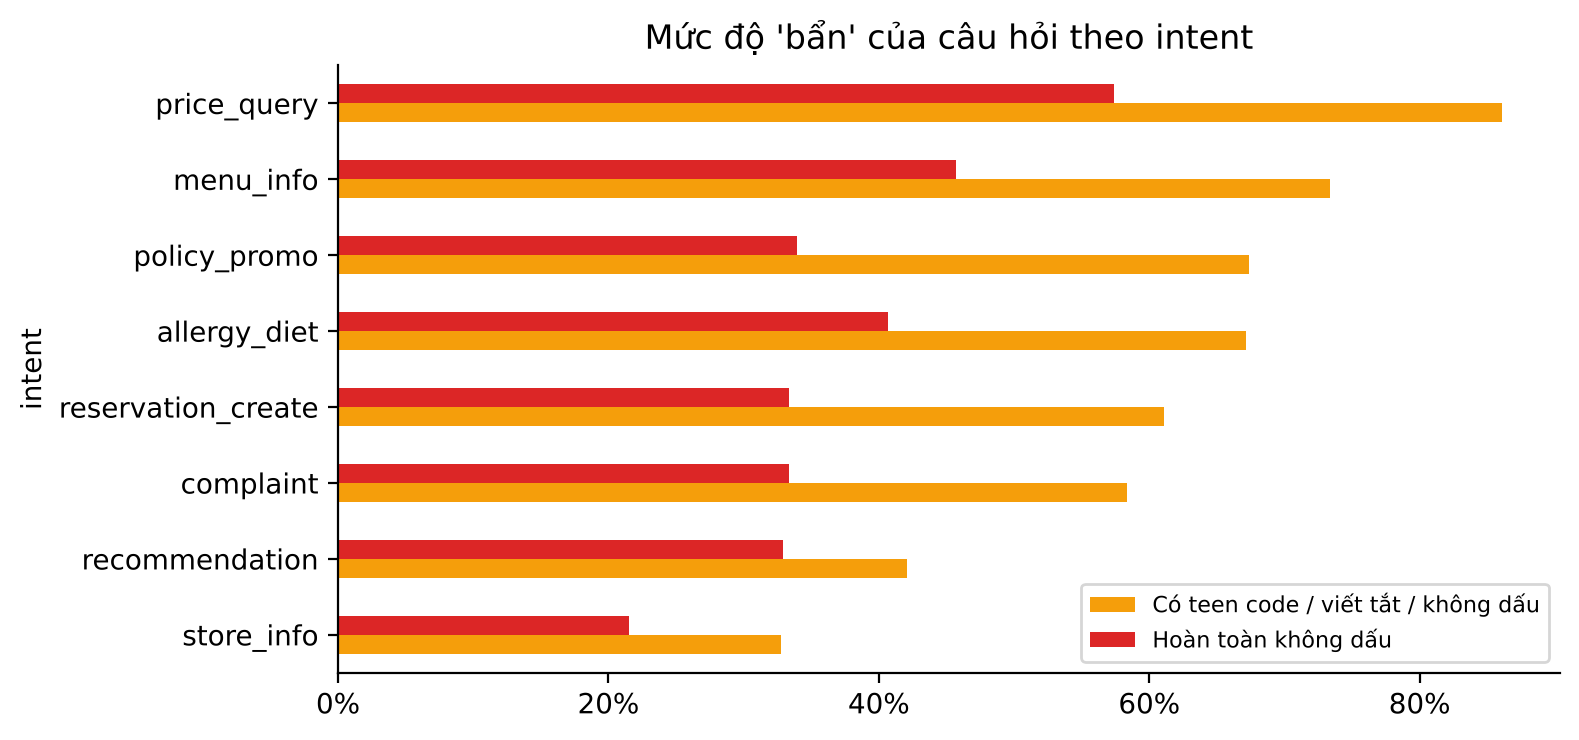

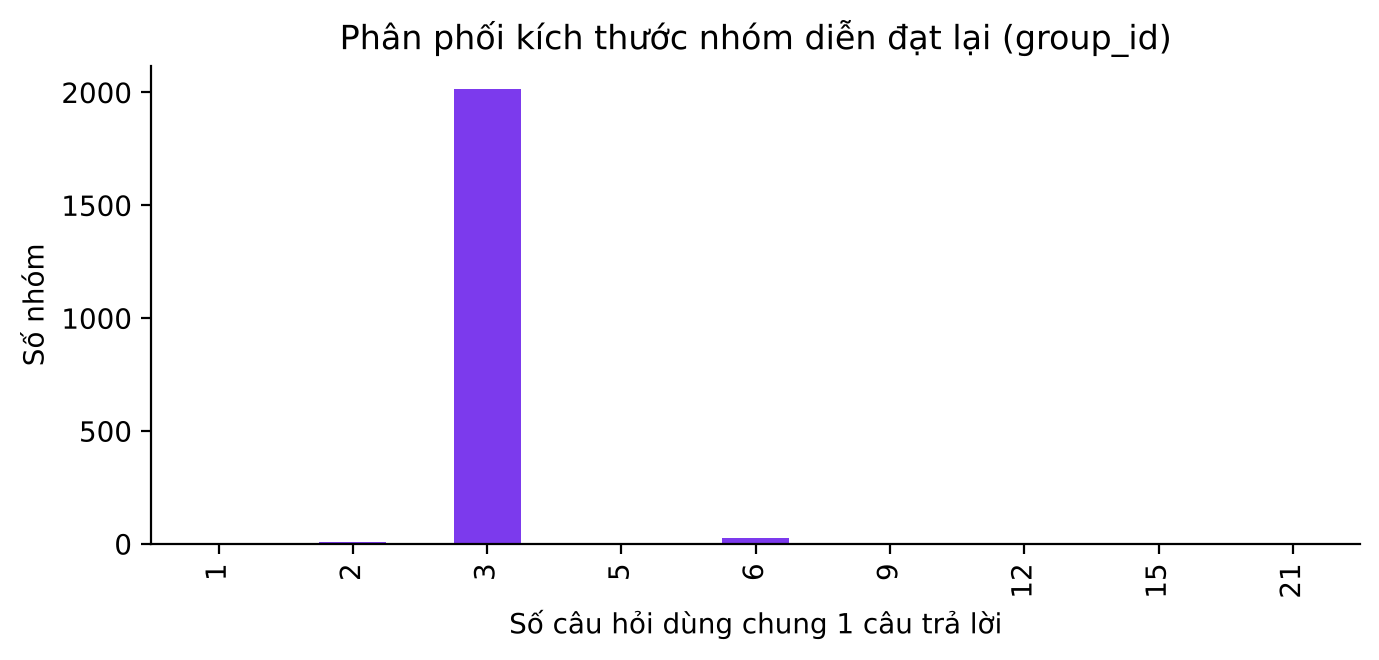

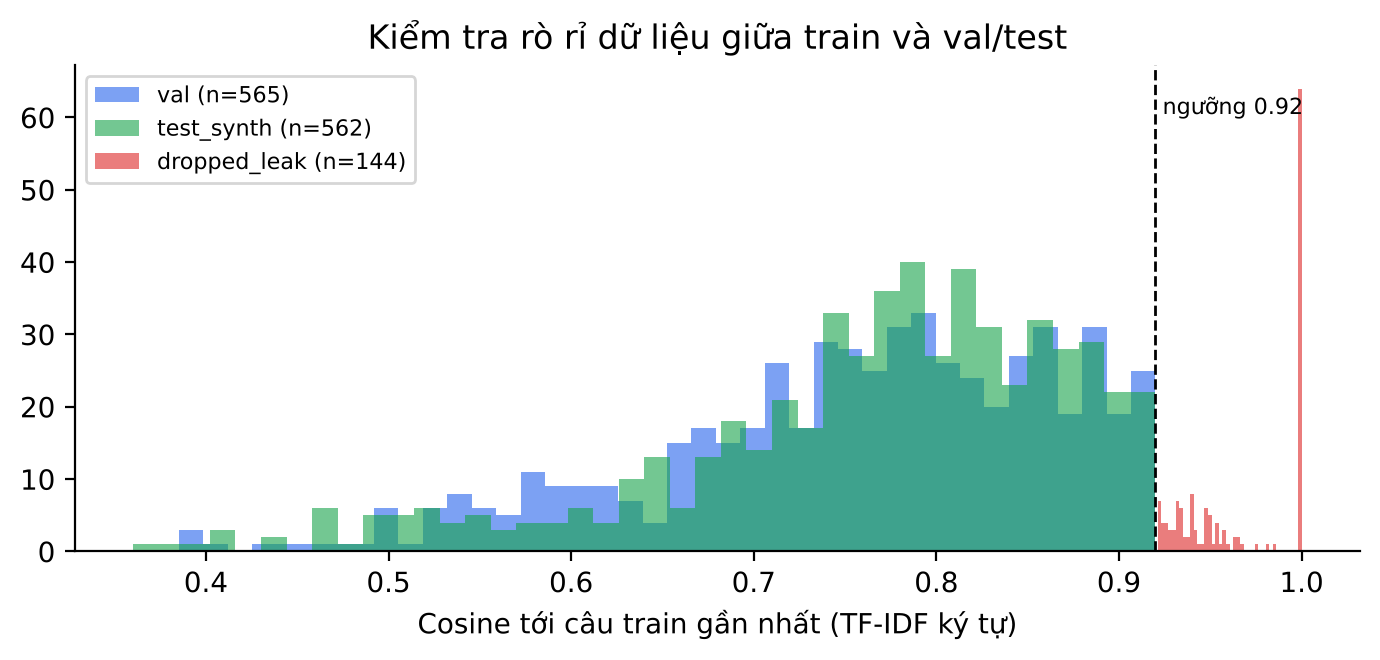

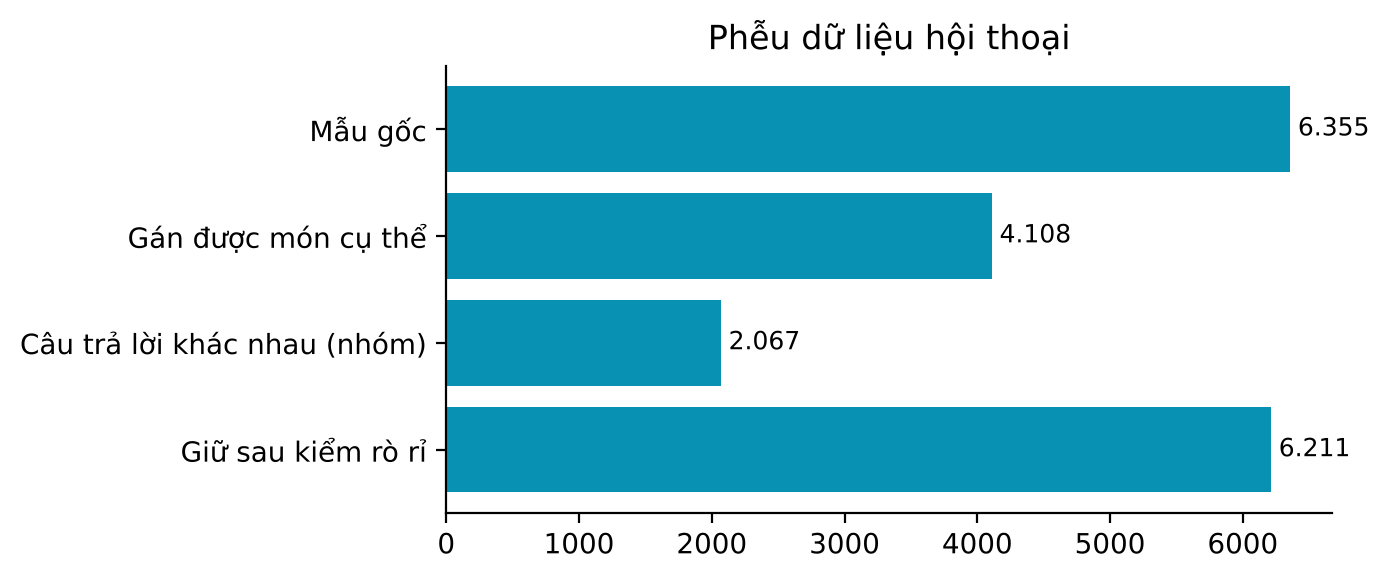

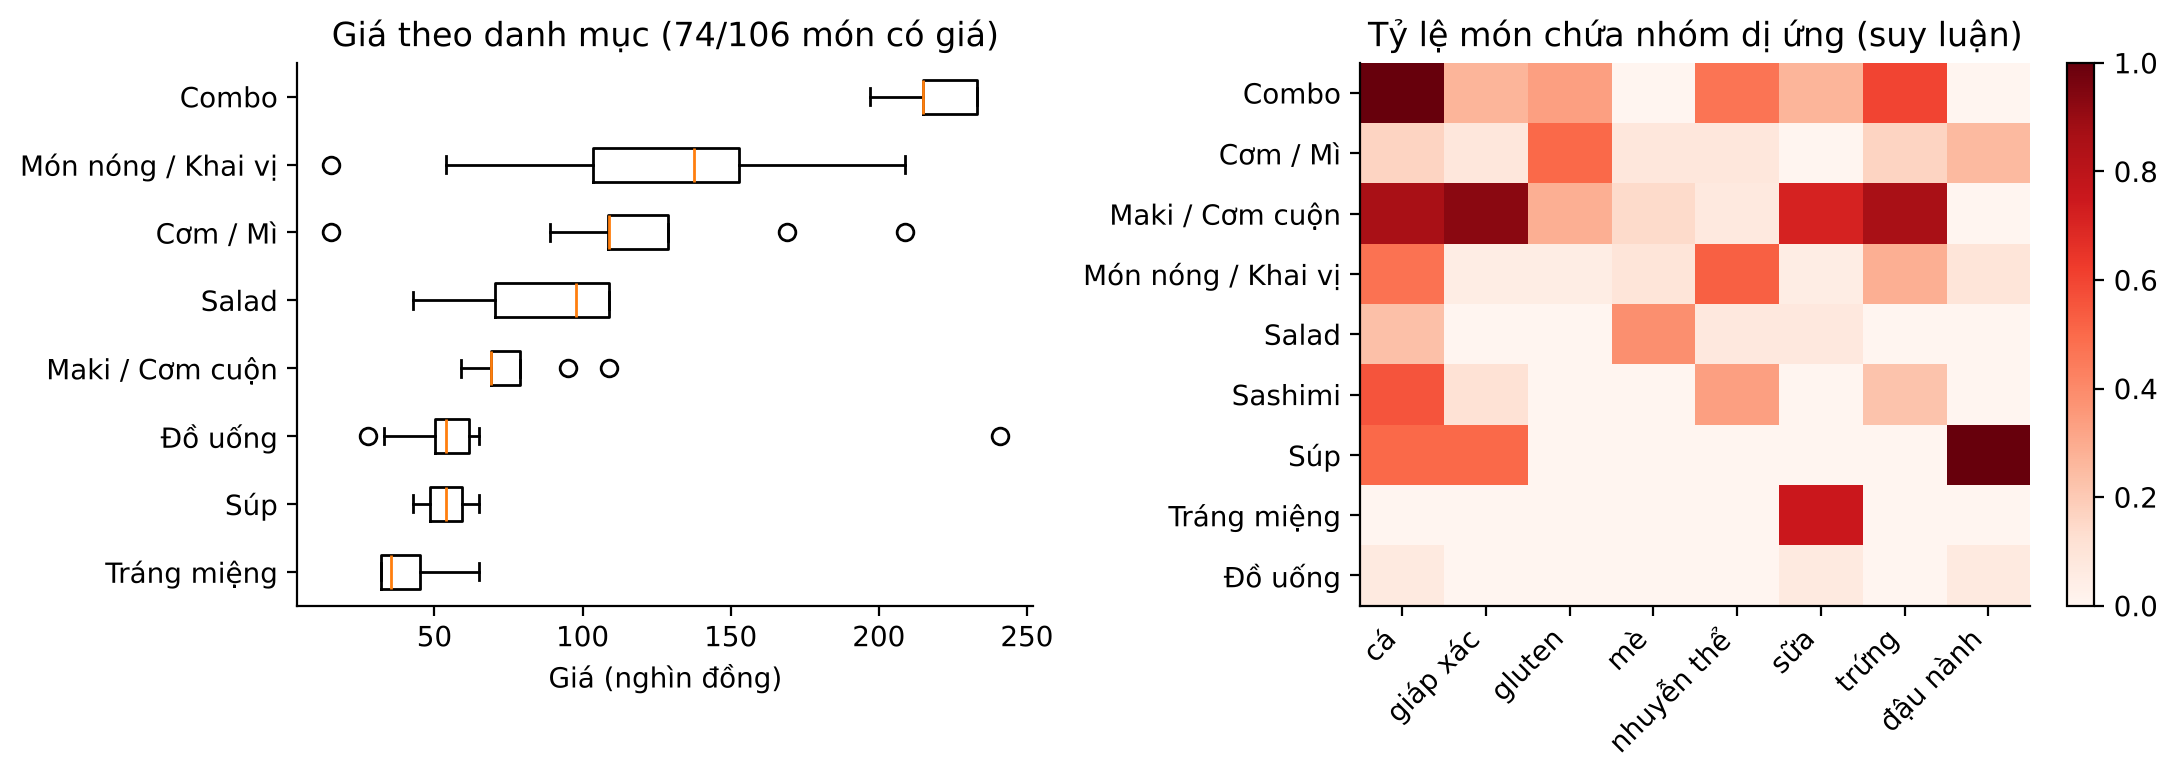

In [3]:
for f in ['eda_intent_split','eda_lengths','eda_noise','eda_group_size','eda_leakage','eda_funnel','eda_menu']:
    display(Image(f'../images/{f}.png', width=750))

In [4]:
st

{'intent': {'share': {'complaint': 0.004,
   'reservation_create': 0.006,
   'store_info': 0.018,
   'policy_promo': 0.035,
   'allergy_diet': 0.125,
   'recommendation': 0.146,
   'price_query': 0.149,
   'menu_info': 0.517},
  'max_abs_share_gap_train_test': 0.023836556526511177},
 'lengths': {'q_mean': np.float64(9.482140047206924),
  'q_p95': np.float64(16.0),
  'q_skew': np.float64(2.121931696373024),
  'a_mean': np.float64(38.84736757365964),
  'a_p95': np.float64(72.0),
  'a_skew': np.float64(1.2640818922930888),
  'a_max': 122},
 'noise': {'noisy_rate': np.float64(0.6884343036978757),
  'unaccented_rate': np.float64(0.43981117230527145)},
 'groups': {'groups': 2067,
  'group_mean': np.float64(3.0745041122399615),
  'share_groups_ge3': 0.9932268988872762},
 'leakage': {'kept_cos_mean': np.float64(0.7605913567963735),
  'kept_cos_max': np.float64(0.9199382828237244)},
 'funnel': {'Mẫu gốc': 6355,
  'Gán được món cụ thể': 4108,
  'Câu trả lời khác nhau (nhóm)': 2067,
  'Giữ sau ki

## Độ dài token theo tokenizer Qwen / LLaMA (chạy trên Colab — cần truy cập Hugging Face)

In [5]:
try:
    from transformers import AutoTokenizer
    q = pd.read_json('../data/splits/train.jsonl', lines=True)
    texts = q.messages.map(lambda m: m[1]['content'] + ' ' + m[2]['content'])
    for name in ['Qwen/Qwen2.5-3B-Instruct', 'unsloth/Llama-3.2-3B-Instruct']:
        tok = AutoTokenizer.from_pretrained(name)
        n = texts.map(lambda t: len(tok(t)['input_ids']))
        print(name, n.describe().round(1).to_dict())
except Exception as e:
    print('Bỏ qua (không truy cập được HF):', type(e).__name__)

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Bỏ qua (không truy cập được HF): OSError
